# CNN — classification PCG sur spectrogrammes Mel


## 1. Chargement, segmentation et spectrogrammes Mel

In [2]:
import json
import random
import sys
import time
from datetime import datetime
from pathlib import Path

# --- localisation du dépôt AVANT les imports locaux : sans cela `preprocess` peut
# résoudre vers un module homonyme installé dans site-packages
DATA_ROOT = next((p / "ourdataset" / "train" for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "ourdataset" / "train").is_dir()), None)
assert DATA_ROOT is not None, f"ourdataset/train introuvable depuis {Path.cwd()}"
AUDIO_ENGINE_DIR = DATA_ROOT.parent.parent / "audio_engine"
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
assert (AUDIO_ENGINE_DIR / "preprocess.py").exists(), f"preprocess.py introuvable dans {AUDIO_ENGINE_DIR}"

import librosa
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split

from preprocess import AudioError, Preprocessor
MODEL_DIR = AUDIO_ENGINE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
PLOT_DIR = MODEL_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)

# --- mêmes paramètres que registry.py (service d'inférence) et analyze_signal.py
SR, N_MELS, N_FFT, HOP, T = 2000, 128, 512, 128, 256
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MEL_CACHE = MODEL_DIR / "tp3_cnn_mels.npy"          # spectrogrammes float16 (mmap)
INDEX_CACHE = MODEL_DIR / "tp3_cnn_mels_index.npz"  # clés "classe/nom.wav" + labels

pre = Preprocessor({"max_segments": 10})


def mel(seg):
    """Mel 128×256 dB, normalisé par segment — identique au service d'inférence."""
    m = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=20, fmax=SR // 2)
    m = librosa.power_to_db(m, ref=np.max)
    m = np.pad(m, ((0, 0), (0, max(0, T - m.shape[1]))))[:, :T].astype(np.float32)
    return (m - m.mean()) / (m.std() + 1e-6)

In [3]:
files = [(p, label) for label, name in enumerate(["normal", "abnormal"])
         for p in sorted((DATA_ROOT / name).glob("*.wav"))]
print(len(files), "fichiers WAV")


def build_mel_cache(force=False):
    """Spectrogrammes de tous les segments (float16 sur disque, rechargés en mmap)."""
    if MEL_CACHE.exists() and INDEX_CACHE.exists() and not force:
        index = np.load(INDEX_CACHE, allow_pickle=True)
        X = np.load(MEL_CACHE, mmap_mode="r")
        print(f"Cache réutilisé : {MEL_CACHE.name} {X.shape} ({X.nbytes / 1e9:.2f} Go, mmap)")
        return X, index["keys"], index["y"].astype(np.int64)

    t0, keys, labels, blocks = time.time(), [], [], []
    for n, (path, label) in enumerate(files, start=1):
        try:
            segments = pre.segment(pre.load_clean(path.read_bytes()))
        except AudioError as error:
            print(f"  ignoré {path.name}: {error}")
            continue
        # float16 : 2× moins de RAM qu'un float32 puis conversion par lot à l'entraînement
        blocks.append(np.stack([mel(s) for s in segments]).astype(np.float16))
        keys += [f"{label}/{path.name}"] * len(segments)
        labels += [label] * len(segments)
        if n % 500 == 0:
            print(f"  {n}/{len(files)} fichiers, {sum(len(b) for b in blocks)} segments "
                  f"({time.time() - t0:.0f} s)")

    X_all = np.concatenate(blocks).astype(np.float16)
    X_all = X_all[:, None, :, :]                      # (N, 1, 128, 256)
    keys_all = np.array(keys, dtype=object)
    y_all = np.array(labels, dtype=np.int64)          # int64 : cible valide pour CrossEntropyLoss
    np.save(MEL_CACHE, X_all)
    np.savez(INDEX_CACHE, keys=keys_all, y=y_all)
    print(f"Cache écrit : {MEL_CACHE.name} {X_all.shape} ({X_all.nbytes / 1e9:.2f} Go) "
          f"en {(time.time() - t0) / 60:.1f} min")
    return X_all, keys_all, y_all


X_mel, keys_all, y_all = build_mel_cache()
print(f"{len(y_all)} segments pour {len(np.unique(keys_all))} enregistrements | "
      f"abnormal = {y_all.mean():.1%} des segments")

3784 fichiers WAV
Cache réutilisé : tp3_cnn_mels.npy (22126, 1, 128, 256) (1.45 Go, mmap)
22126 segments pour 3781 enregistrements | abnormal = 23.3% des segments


## 2. Split par enregistrement (70 / 15 / 15)

Le découpage se fait **au niveau du WAV**, pas du segment : sinon des segments quasi identiques
d'un même enregistrement se retrouveraient en entraînement et en test (fuite de données).

In [4]:
recording_keys = np.array(sorted(np.unique(keys_all)))
recording_label = np.array([int(k[0]) for k in recording_keys])

idx_tr, idx_tmp = train_test_split(np.arange(len(recording_keys)), test_size=0.30,
                                   stratify=recording_label, random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50,
                                  stratify=recording_label[idx_tmp], random_state=SEED)

keys_tr = set(recording_keys[idx_tr])
keys_va = set(recording_keys[idx_va])
keys_te = set(recording_keys[idx_te])

# positions des segments correspondants dans le cache (aucune copie mémoire)
positions_par_cle = {}
for position, key in enumerate(keys_all):
    positions_par_cle.setdefault(key, []).append(position)

pos_tr = np.array(sorted(p for k in keys_tr for p in positions_par_cle[k]), dtype=np.int64)
pos_va = np.array(sorted(p for k in keys_va for p in positions_par_cle[k]), dtype=np.int64)
pos_te = np.array(sorted(p for k in keys_te for p in positions_par_cle[k]), dtype=np.int64)

for name, keys, pos in (("train", keys_tr, pos_tr), ("val", keys_va, pos_va), ("test", keys_te, pos_te)):
    print(f"{name:<5} : {len(keys):>4} enregistrements | {len(pos):>5} segments | "
          f"abnormal = {y_all[pos].mean():.1%}")

train : 2646 enregistrements | 15356 segments | abnormal = 22.7%
val   :  567 enregistrements |  3340 segments | abnormal = 24.2%
test  :  568 enregistrements |  3430 segments | abnormal = 25.1%


## 3. Modèle (petit CNN)

L'architecture vit dans `src/model_cnn_lite.py` (`CardioCNNLite`) : elle est ainsi importable par le
service d'inférence et sérialisable par MLflow, contrairement à une classe définie dans le notebook.

In [5]:
from src.model_cnn_lite import CardioCNNLite

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
model = CardioCNNLite(n_classes=2).to(dev)
n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params:,} paramètres | device = {dev}".replace(",", " "))

421 474 paramètres | device = cuda


## 4. Entraînement (poids de classes, meilleur epoch selon l'AUC validation)

In [6]:
def predict_positions(positions, bs=64):
    """P(abnormal) par segment ; lecture du cache Mel par lots (float16 → float32)."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(positions), bs):
            batch = np.asarray(X_mel[positions[i:i + bs]], dtype=np.float32)
            xb = torch.from_numpy(batch).to(dev)
            out.append(torch.softmax(model(xb), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)


w = torch.tensor(len(pos_tr) / (2 * np.bincount(y_all[pos_tr])), dtype=torch.float32, device=dev)
loss_fn = nn.CrossEntropyLoss(weight=w)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

best_auc, best_state, best_epoch, history = 0.0, None, 0, []
EPOCHS, BS, PATIENCE = 15, 16, 3

for epoch in range(1, EPOCHS + 1):
    model.train()
    order = np.random.permutation(len(pos_tr))
    total = 0.0
    for i in range(0, len(order), BS):
        batch_pos = pos_tr[order[i:i + BS]]
        xb = torch.from_numpy(np.asarray(X_mel[batch_pos], dtype=np.float32)).to(dev)
        yb = torch.from_numpy(y_all[batch_pos]).to(dev)   # int64 -> cible valide
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(batch_pos)   # .item() : pas de warning requires_grad

    val_auc = roc_auc_score(y_all[pos_va], predict_positions(pos_va))
    history.append({"epoch": epoch, "train_loss": total / len(pos_tr), "val_auc": float(val_auc)})
    print(f"epoch {epoch:2d} | loss={total / len(pos_tr):.4f} | val AUC={val_auc:.3f}")

    if val_auc > best_auc + 1e-5:
        best_auc, best_epoch = float(val_auc), epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    elif epoch - best_epoch >= PATIENCE:
        print(f"arrêt anticipé : pas d'amélioration depuis {PATIENCE} epochs")
        break

model.load_state_dict(best_state)
print(f"meilleur epoch = {best_epoch} | val AUC = {best_auc:.3f}")

epoch  1 | loss=0.6000 | val AUC=0.891
epoch  2 | loss=0.4214 | val AUC=0.923
epoch  3 | loss=0.3705 | val AUC=0.934
epoch  4 | loss=0.3450 | val AUC=0.940
epoch  5 | loss=0.3271 | val AUC=0.953
epoch  6 | loss=0.3119 | val AUC=0.960
epoch  7 | loss=0.2950 | val AUC=0.957
epoch  8 | loss=0.2937 | val AUC=0.957
epoch  9 | loss=0.2754 | val AUC=0.961
epoch 10 | loss=0.2810 | val AUC=0.960
epoch 11 | loss=0.2641 | val AUC=0.965
epoch 12 | loss=0.2578 | val AUC=0.958
epoch 13 | loss=0.2557 | val AUC=0.968
epoch 14 | loss=0.2481 | val AUC=0.964
epoch 15 | loss=0.2419 | val AUC=0.966
meilleur epoch = 13 | val AUC = 0.968


## 5. Seuil (validation) puis évaluation (test)

Le seuil est choisi sur la validation en maximisant le rappel sous contrainte de spécificité ≥ 0,80 :
c'est le compromis retenu pour un outil de dépistage.

In [7]:
def select_threshold(y_val, p_val, min_spec=0.80):
    fpr, tpr, thr = roc_curve(y_val, p_val, drop_intermediate=False)
    ok = np.isfinite(thr) & (thr <= 1) & ((1 - fpr) >= min_spec)
    if ok.any():
        i = np.where(ok)[0]
        return float(thr[i[np.argmax(tpr[i])]])
    return 0.5


def classification_metrics(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_precision": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, proba)),
        "threshold": float(threshold),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }


p_va = predict_positions(pos_va)
p_te = predict_positions(pos_te)
y_va, y_te = y_all[pos_va], y_all[pos_te]
THRESHOLD = select_threshold(y_va, p_va)

val_metrics = classification_metrics(y_va, p_va, THRESHOLD)
test_metrics = classification_metrics(y_te, p_te, THRESHOLD)

for name, m in (("validation", val_metrics), ("test", test_metrics)):
    print(f"{name:<10} seuil={m['threshold']:.3f} | AUC={m['auc']:.3f} | exactitude={m['accuracy']:.3f} | "
          f"BA={m['balanced_accuracy']:.3f} | macro F1={m['macro_f1']:.3f} | "
          f"rappel={m['recall']:.3f} | spécificité={m['specificity']:.3f}")
print("test :", test_metrics["confusion"])

validation seuil=0.309 | AUC=0.968 | exactitude=0.847 | BA=0.895 | macro F1=0.823 | rappel=0.988 | spécificité=0.802
test       seuil=0.309 | AUC=0.946 | exactitude=0.832 | BA=0.884 | macro F1=0.811 | rappel=0.987 | spécificité=0.780
test : {'tn': 2004, 'fp': 564, 'fn': 11, 'tp': 851}


## 6. Courbes et matrices de confusion

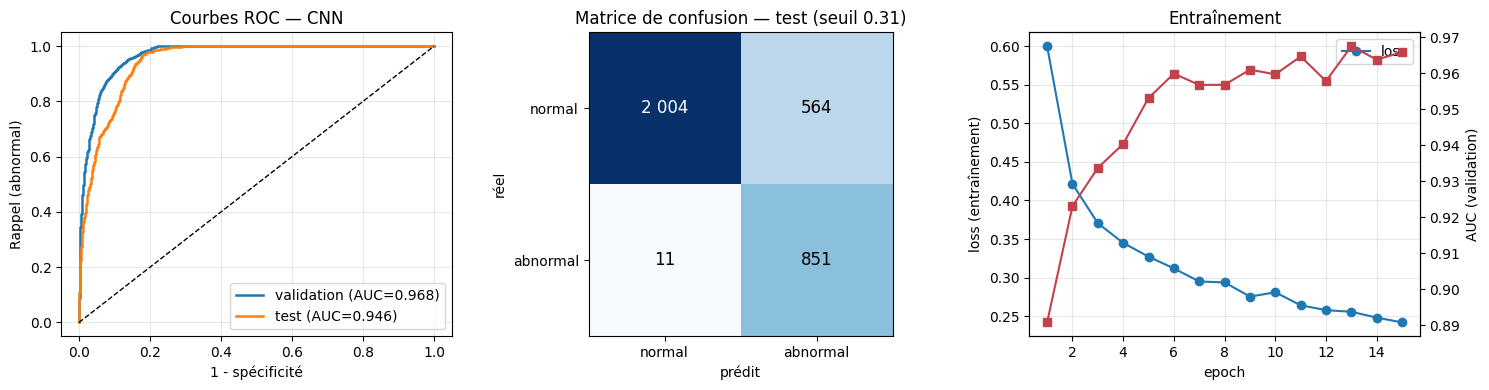

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for name, (yy, pp) in {"validation": (y_va, p_va), "test": (y_te, p_te)}.items():
    fpr, tpr, _ = roc_curve(yy, pp)
    axes[0].plot(fpr, tpr, lw=1.8, label=f"{name} (AUC={roc_auc_score(yy, pp):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("1 - spécificité")
axes[0].set_ylabel("Rappel (abnormal)")
axes[0].set_title("Courbes ROC — CNN")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

cm = confusion_matrix(y_te, (p_te >= THRESHOLD).astype(int), labels=[0, 1])
axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm[i, j]:,}".replace(",", " "), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
axes[1].set_xticks([0, 1], ["normal", "abnormal"])
axes[1].set_yticks([0, 1], ["normal", "abnormal"])
axes[1].set_xlabel("prédit")
axes[1].set_ylabel("réel")
axes[1].set_title(f"Matrice de confusion — test (seuil {THRESHOLD:.2f})")

axes[2].plot([h["epoch"] for h in history], [h["train_loss"] for h in history], marker="o", label="loss")
ax2 = axes[2].twinx()
ax2.plot([h["epoch"] for h in history], [h["val_auc"] for h in history], marker="s",
         color="#c2414b", label="AUC validation")
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("loss (entraînement)")
ax2.set_ylabel("AUC (validation)")
axes[2].set_title("Entraînement")
axes[2].grid(alpha=0.3)
axes[2].legend(loc="upper right")

fig.tight_layout()
CNN_ROC_PLOT = PLOT_DIR / "tp3_cnn_roc_confusion.png"
fig.savefig(CNN_ROC_PLOT, dpi=150)
plt.show()

## 7. Évaluation au niveau enregistrement (test)

Le modèle décide par segment : on agrège en moyennant les probabilités des segments d'un même WAV,
comme le fait le service d'inférence (`registry.py`).

In [9]:
def aggregate_by_recording(positions, probs):
    per_key = {}
    for pos, proba in zip(positions, probs):
        per_key.setdefault(keys_all[pos], []).append(float(proba))
    keys = sorted(per_key)
    return keys, np.array([np.mean(per_key[k]) for k in keys])


test_names, p_rec = aggregate_by_recording(pos_te, p_te)
y_rec = np.array([int(k[0]) for k in test_names])
pred_rec = (p_rec >= THRESHOLD).astype(int)

print(f"Au niveau enregistrement ({len(y_rec)} WAV de test) : "
      f"exactitude={accuracy_score(y_rec, pred_rec):.3f}  "
      f"BA={balanced_accuracy_score(y_rec, pred_rec):.3f}  "
      f"AUC={roc_auc_score(y_rec, p_rec):.3f}")
for name, label in (("normal", 0), ("abnormal", 1)):
    sel = y_rec == label
    print(f"  {name:<8} : {sel.sum():>4} WAV, rappel={pred_rec[sel].mean():.3f}")

Au niveau enregistrement (568 WAV de test) : exactitude=0.725  BA=0.817  AUC=0.906
  normal   :  439 WAV, rappel=0.351
  abnormal :  129 WAV, rappel=0.984


## 8. Sauvegarde du modèle

`models/best_cnn.pt` contient le `state_dict` (petit fichier, rechargeable via `CardioCNNLite`) et
`models/best_cnn_meta.json` les métadonnées lues par le service d'inférence : architecture, seuil,
paramètres Mel et métriques.

In [10]:
CNN_MODEL_PATH = MODEL_DIR / "best_cnn.pt"
CNN_META_PATH = MODEL_DIR / "best_cnn_meta.json"
torch.save(model.state_dict(), CNN_MODEL_PATH)

meta = {
    "model": "CNN",
    "architecture": "CardioCNNLite",
    "file": str(CNN_MODEL_PATH),
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "threshold": THRESHOLD,
    "decision": {"kind": "softmax", "aggregation": "moyenne des P(abnormal) des segments du WAV"},
    "metrics": {"val": val_metrics, "test": test_metrics},
    "recording_level_test": {
        "n_recordings": int(len(y_rec)),
        "accuracy": float(accuracy_score(y_rec, pred_rec)),
        "balanced_accuracy": float(balanced_accuracy_score(y_rec, pred_rec)),
        "auc": float(roc_auc_score(y_rec, p_rec)),
    },
    "protocol": "split 70/15/15 par enregistrement (random_state=42), cible = segments de 5 s",
    "history": history,
    "mel": {"sr": SR, "n_mels": N_MELS, "n_fft": N_FFT, "hop_length": HOP,
            "target_time_frames": T, "fmin": 20, "fmax": SR // 2,
            "db": "power_to_db(ref=np.max)", "normalisation": "centrée-réduite par segment"},
    "n_segments": {"train": int(len(pos_tr)), "val": int(len(pos_va)), "test": int(len(pos_te))},
    "n_recordings": {"train": len(keys_tr), "val": len(keys_va), "test": len(keys_te)},
    "class_counts": {"normal": int((y_all == 0).sum()), "abnormal": int((y_all == 1).sum())},
    "labels": {"0": "normal", "1": "abnormal"},
    "versions": {"torch": torch.__version__, "librosa": librosa.__version__, "numpy": np.__version__},
    "usage": "model = CardioCNNLite(); model.load_state_dict(torch.load('models/best_cnn.pt', "
             "map_location='cpu')); model.eval() -- ou registry.predict_segments('cnn', segments)",
}
CNN_META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

# --- vérification : rechargement depuis le disque
check = CardioCNNLite()
check.load_state_dict(torch.load(CNN_MODEL_PATH, map_location="cpu"))
check.eval()
print(f"Poids sauvegardés : {CNN_MODEL_PATH} ({CNN_MODEL_PATH.stat().st_size / 1e6:.2f} Mo)")
print(f"Métadonnées       : {CNN_META_PATH} (seuil = {THRESHOLD:.3f})")

Poids sauvegardés : c:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_cnn.pt (1.70 Mo)
Métadonnées       : c:\Users\Admin\Desktop\Semester_1_3GMAM\Data Mining\audio_engine\models\best_cnn_meta.json (seuil = 0.309)


C:\Users\Admin\AppData\Local\Temp\ipykernel_10156\2555640704.py:36: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  check.load_state_dict(torch.load(CNN_MODEL_PATH, map_locati

## 9. Suivi MLflow

Même expérience que le SVM (`SVM.ipynb`) et l'arbre de décision (`DECISIONTREE.ipynb`) :
`tp3_audio_engine`. Les trois runs (`svm_rbf_segments`, `decision_tree_gridsearch`,
`cnn_mel_segments`) sont donc directement comparables dans l'interface MLflow, et le service
d'inférence (`audio_engine/registry.py`) charge ces trois modèles pour l'interface web.

In [11]:
import sys
sys.path.insert(0, str(AUDIO_ENGINE_DIR))
from mlflow_utils import log_torch_run

mlflow_params = {
    "model": "CNN",
    "architecture": "CardioCNNLite",
    "optimizer": "Adam(lr=1e-3)",
    "loss": "CrossEntropyLoss(poids de classes)",
    "batch_size": BS,
    "max_epochs": EPOCHS,
    "best_epoch": best_epoch,
    "early_stopping_patience": PATIENCE,
    "input": "Mel 128x256 normalisé par segment",
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP,
    "target_time_frames": T,
    "sample_rate": SR,
    "segment_seconds": pre.seg_len / pre.sr,
    "hop_seconds": pre.hop_len / pre.sr,
    "n_segments_train": int(len(pos_tr)),
    "n_segments_val": int(len(pos_va)),
    "n_segments_test": int(len(pos_te)),
    "n_recordings": int(len(recording_keys)),
    "threshold": THRESHOLD,
    "seed": SEED,
    "split": "70/15/15 par enregistrement",
}

mlflow_metrics = {
    "accuracy": test_metrics["accuracy"],
    "balanced_accuracy": test_metrics["balanced_accuracy"],
    "macro_precision": test_metrics["macro_precision"],
    "macro_recall": test_metrics["macro_recall"],
    "macro_f1": test_metrics["macro_f1"],
    "roc_auc": test_metrics["auc"],
    "recall_abnormal": test_metrics["recall"],
    "specificity_abnormal": test_metrics["specificity"],
    "threshold": THRESHOLD,
    "val_auc": val_metrics["auc"],
    "val_balanced_accuracy": val_metrics["balanced_accuracy"],
    "test_recording_balanced_accuracy": meta["recording_level_test"]["balanced_accuracy"],
    "best_epoch": float(best_epoch),
}

tracking_uri, run_id = log_torch_run(
    run_name="cnn_mel_segments",
    model=model,
    params=mlflow_params,
    mean_metrics=mlflow_metrics,
    artifacts={CNN_MODEL_PATH: "models", CNN_META_PATH: "models", CNN_ROC_PLOT: "plots"},
    input_example=np.asarray(X_mel[pos_te[:4]], dtype=np.float32),
)

2026/11/17 14:46:28 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: RuntimeError('Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor'). To see the full traceback, set the logging level to DEBUG via `logging.getLogger("mlflow").setLevel(logging.DEBUG)`. To disable automatic signature inference, set `signature` to `False` in your `log_model` or `save_model` call.
2026/11/17 14:46:28 WARNING mlflow.utils.requirements_utils: Found torch version (2.5.1+cu121) contains a local version label (+cu121). MLflow logged a pip requirement for this package as 'torch==2.5.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/17 14:46:42 WARNING mlflow.utils.requirements_utils: Found torch version (2.5.1+cu121) contains

2026/11/17 14:46:44 WARNING mlflow.models.model: Failed to validate serving input example {
  "inputs": [
    [
      [
        [
          -0.493408203125,
          -0.367431640625,
          -0.317626953125,
          -0.2021484375,
          -0.135009765625,
          -0.2083740234375,
          -0.16357421875,
          0.06341552734375,
          0.053741455078125,
          -0.163818359375,
          -0.45263671875,
          -0.241455078125,
          -0.1375732421875,
          -0.08087158203125,
          -0.2452392578125,
          -0.460693359375,
          -0.470947265625,
          -0.4814453125,
          -0.2037353515625,
          0.01203155517578125,
          -0.0304107666015625,
          -0.331787109375,
          -0.407470703125,
          -0.1905517578125,
          0.03546142578125,
          0.0406494140625,
          -0.1669921875,
          -0.5146484375,
          -0.28369140625,
          -0.313232421875,
          0.130859375,
          0.2308349609375,
  

[MLflow] run 'cnn_mel_segments' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/339b9bf971d54ec59651ae2e60b1e59a
[MLflow] run_id = 339b9bf971d54ec59651ae2e60b1e59a



### Architecture du modèle CNN

Le modèle CNN est composé de 4 blocs convolutionnels suivis de couches de classification.

| Couche | Architecture | Dimension de sortie | Paramètres |
|---|---|---|---:|
| Entrée | Input | (B, 1, 128, 256) | 0 |
| Bloc 1 | Conv2D (1 → 32, 3×3) + BatchNorm + ReLU + MaxPool | (B, 32, 64, 128) | 352 |
| Bloc 2 | Conv2D (32 → 64, 3×3) + BatchNorm + ReLU + MaxPool + Dropout (0.1) | (B, 64, 32, 64) | 18 560 |
| Bloc 3 | Conv2D (64 → 128, 3×3) + BatchNorm + ReLU + MaxPool + Dropout (0.2) | (B, 128, 16, 32) | 73 984 |
| Bloc 4 | Conv2D (128 → 256, 3×3) + BatchNorm + ReLU + MaxPool + Dropout (0.3) | (B, 256, 8, 16) | 295 424 |
| Pooling | AdaptiveAvgPool2D (1×1) | (B, 256, 1, 1) | 0 |
| Flatten | Flatten | (B, 256) | 0 |
| FC1 | Linear (256 → 128) + ReLU + Dropout (0.3) | (B, 128) | 32 896 |
| FC2 | Linear (128 → 2) | (B, 2) | 258 |

**Nombre total de paramètres entraînables : 421 474**

**Description de l'architecture :**
- Les couches Conv2D extraient progressivement les caractéristiques spatiales du Mel-Spectrogram.
- Batch Normalization stabilise et accélère l'entraînement.
- ReLU introduit la non-linéarité.
- MaxPooling réduit les dimensions spatiales.
- Dropout limite le surapprentissage (Overfitting).
- Adaptive Average Pooling réduit chaque carte de caractéristiques à une dimension de 1×1.
- Flatten transforme les caractéristiques en vecteur.
- Les couches Fully Connected réalisent la classification finale en deux classes.

**Sortie :** 2 neurones correspondant aux deux classes de classification.


Donner la courbe d'entrainnement de chaque folder et le metter dans le mlflow 
